In [141]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.metrics import precision_score, accuracy_score, recall_score
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from matplotlib.colors import ListedColormap
from sklearn.model_selection import StratifiedKFold, cross_val_score

csv_file = 'iris.csv'
df = pd.read_csv(csv_file)

df.info()
df.head(10)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            150 non-null    int64  
 1   sepal_length  150 non-null    float64
 2   sepal_width   150 non-null    float64
 3   petal_length  150 non-null    float64
 4   petal_width   150 non-null    float64
 5   species       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


,id,sepal_length,sepal_width,petal_length,petal_width,species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
5,6,5.4,3.9,1.7,0.4,Iris-setosa
6,7,4.6,3.4,1.4,0.3,Iris-setosa
7,8,5.0,3.4,1.5,0.2,Iris-setosa
8,9,4.4,2.9,1.4,0.2,Iris-setosa
9,10,4.9,3.1,1.5,0.1,Iris-setosa


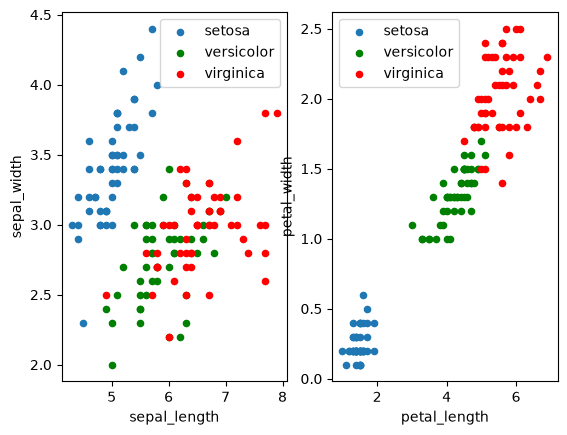

In [97]:
# divide the dataset into three dataframes based on the species
setosa_df = df.query('species == "Iris-setosa"')
versicolor_df = df.query('species == "Iris-versicolor"')
virginica_df = df.query('species == "Iris-virginica"')

fig, axes = plt.subplots(nrows=1, ncols=2)

# Plot a scatter chart using x='sepal_length', y='sepal_width', and separate colors for each of the three dataframes
ax = setosa_df.plot.scatter(x='sepal_length', y='sepal_width', label='setosa', ax=axes[0])
ax = versicolor_df.plot.scatter(x='sepal_length', y='sepal_width', label='versicolor', color='green', ax=ax)
ax = virginica_df.plot.scatter(x='sepal_length', y='sepal_width', label='virginica', color='red', ax=ax)

# Plot a scatter chart using x='petal_length', y='petal_width', and separate colors for each of the three dataframes
ax = setosa_df.plot.scatter(x='petal_length', y='petal_width', label='setosa', ax=axes[1])
ax = versicolor_df.plot.scatter(x='petal_length', y='petal_width', label='versicolor', color='green', ax=ax)
ax = virginica_df.plot.scatter(x='petal_length', y='petal_width', label='virginica', color='red', ax=ax)

plt.show()


In [142]:
# generate the training set and test set
def load_iris(iris_path, split_percentage, features):
    df = pd.read_csv(iris_path)
    df = shuffle(df, random_state=48)

    iris_x = df.loc[:, features]
    iris_y = df["species"].to_numpy()

    split_point = int(len(iris_x) * split_percentage)

    iris_X_train = iris_x.iloc[:split_point]
    iris_y_train = iris_y[:split_point]
    iris_X_test = iris_x.iloc[split_point:]
    iris_y_test = iris_y[split_point:]

    return iris_X_train, iris_y_train, iris_X_test, iris_y_test


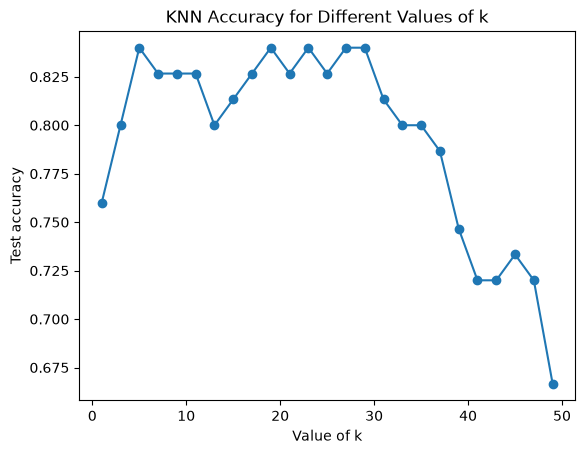

Best k: 50
Test accuracy: 0.6133333333333333


In [149]:
if __name__ == "__main__":
    csv_file = "iris.csv"
    
    
    #features = ["petal_length", "petal_width"]
    features = ["sepal_length", "sepal_width"]
    #features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

    iris_X_train, iris_y_train, iris_X_test, iris_y_test = load_iris(csv_file, split_percentage=0.5,features=features)

    # Try different values of k
    k_range = range(1, 50, 2)
    scores_list = []

    for k in k_range:
        model = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=k)
        )
        model.fit(iris_X_train, iris_y_train)
        predictions = model.predict(iris_X_test)
        scores_list.append(accuracy_score(iris_y_test, predictions))

    # Plot test accuracy for each k
    plt.figure()
    plt.plot(list(k_range), scores_list, marker="o")
    plt.xlabel("Value of k")
    plt.ylabel("Test accuracy")
    plt.title("KNN Accuracy for Different Values of k")
    plt.show()

    # Select the k with the highest test accuracy and fit the model
    best_k = 50 #list(k_range)[np.argmax(scores_list)]
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=best_k)
    )
    knn.fit(iris_X_train, iris_y_train)
    predictions = knn.predict(iris_X_test)

    print("Best k:", best_k)
    print("Test accuracy:", accuracy_score(iris_y_test, predictions))


In [150]:
# function to plot the decision boundary
def plot_knn_boundary(model, X_train, y_train, plot_features, fixed_values=None, resolution=300):
    if len(plot_features) != 2:
        raise ValueError("plot_features must contain exactly two feature names.")

    feature_x, feature_y = plot_features
    fixed_values = fixed_values or {}

    # Set the other features to their training-set medians
    base_values = X_train.median()
    for feature, value in fixed_values.items():
        if feature not in X_train.columns:
            raise ValueError(f"Unknown feature: {feature}")
        base_values[feature] = value

    # Make a grid across the two selected features
    x_min, x_max = X_train[feature_x].min() - 0.5, X_train[feature_x].max() + 0.5
    y_min, y_max = X_train[feature_y].min() - 0.5, X_train[feature_y].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution)
    )

    # Give every grid point the fixed values for the remaining features
    grid = {
        feature: np.full(xx.size, base_values[feature])
        for feature in X_train.columns
    }
    grid[feature_x] = xx.ravel()
    grid[feature_y] = yy.ravel()

    grid_df = pd.DataFrame(grid, columns=X_train.columns)
    grid_predictions = model.predict(grid_df)

    # Encode class labels for contour plotting
    classes = np.unique(y_train)
    class_to_number = {label: i for i, label in enumerate(classes)}
    zz = np.array([class_to_number[label] for label in grid_predictions])
    zz = zz.reshape(xx.shape)

    region_cmap = ListedColormap(
        plt.cm.Pastel1(np.linspace(0, 1, len(classes)))
    )
    point_colors = plt.cm.Dark2(np.linspace(0, 1, len(classes)))

    plt.figure(figsize=(8, 6))
    plt.contourf(
        xx, yy, zz,
        levels=np.arange(len(classes) + 1) - 0.5,
        cmap=region_cmap,
        alpha=0.8
    )

    # Show the training observations projected onto the two plotted features
    y_array = np.asarray(y_train)
    for i, label in enumerate(classes):
        mask = y_array == label
        plt.scatter(
            X_train.loc[mask, feature_x],
            X_train.loc[mask, feature_y],
            color=point_colors[i],
            edgecolor="black",
            label=label
        )

    plt.xlabel(feature_x)
    plt.ylabel(feature_y)
    plt.title("KNN Decision Boundary Slice")
    plt.legend(title="Species")
    plt.show()

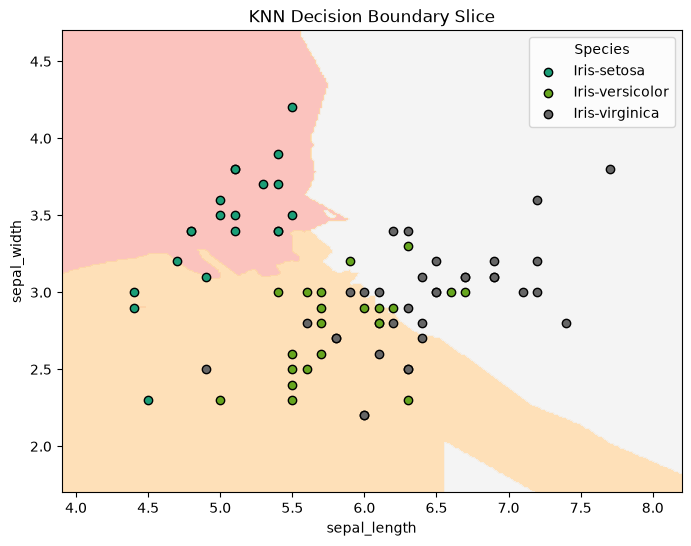

In [151]:
# Plot sepal length and width; other features are held at their medians
plot_knn_boundary(knn,iris_X_train,iris_y_train,plot_features=["sepal_length", "sepal_width"])

# cross validation

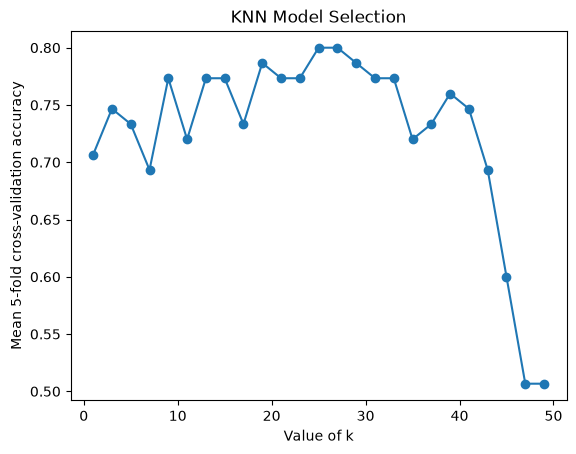

Best k: 27
Mean 5-fold CV accuracy: 0.8000000000000002
Test accuracy: 0.84


In [152]:
# use 5-fold cross validation
# Compare k values using 5-fold cross-validation on the training data
k_range = range(1, 50, 2)
cv_scores = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=48)

for k in k_range:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(model,iris_X_train,iris_y_train,cv=cv,scoring="accuracy")
    cv_scores.append(scores.mean())

# Select the k with the highest mean cross-validation accuracy
best_k = list(k_range)[np.argmax(cv_scores)]
best_cv_score = max(cv_scores)

plt.figure()
plt.plot(list(k_range), cv_scores, marker="o")
plt.xlabel("Value of k")
plt.ylabel("Mean 5-fold cross-validation accuracy")
plt.title("KNN Model Selection")
plt.show()

# Fit the selected model on all training data
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k)
)
knn.fit(iris_X_train, iris_y_train)

# Evaluate once on the held-out test set
predictions = knn.predict(iris_X_test)

print("Best k:", best_k)
print("Mean 5-fold CV accuracy:", best_cv_score)
print("Test accuracy:", accuracy_score(iris_y_test, predictions))

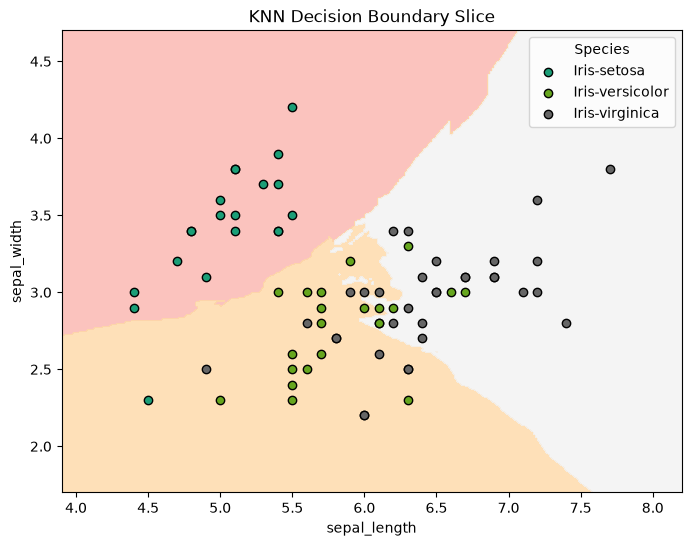

In [153]:
# Plot sepal length and width; other features are held at their medians
plot_knn_boundary(knn,iris_X_train,iris_y_train,plot_features=["sepal_length", "sepal_width"])